# Proyecto Final Integrador: clasificación de una etiqueta simulada de alcohol
**Universidad EAN · Machine Learning I · CRISP-DM**

Equipo: Oscar Andrés Ramos Villanueva, Alvaro Cabezas y Nelsón Fabián Manios.

**Resultado metodológico, no clínico.** Los predictores proceden de registros VESPA,
pero `Alcohol` se genera mediante reglas y aleatoriedad. Ninguna métrica de este
cuaderno demuestra detección real, causalidad, prevalencia poblacional ni riesgo futuro.
Un caso real puede involucrar varias sustancias. La dicotomía aquí es una simplificación simulada.

Ejecute desde esta carpeta, con Python 3.12 y las versiones de `requirements.txt`.
La última evaluación usa un núcleo nuevo. Todos los archivos se leen con rutas relativas.
No requiere Drive, credenciales ni conexión de red para el análisis.

## 1. Comprensión del negocio · R10
El destinatario hipotético es la Secretaría Distrital de Salud de Bogotá. La decisión
explorada es cómo priorizar evaluaciones bajo errores asimétricos. No se recomienda
usar este modelo para asignar recursos reales: falta un resultado observado válido.

La pérdida de entrenamiento es propia de cada algoritmo; la métrica de selección es
el costo simulado por registro `(5 FN + FP) / n`, con Alcohol=1. La razón 5:1 es un
supuesto académico, no un costo oficial. Se evalúan además razones 1, 2 y 10.
La referencia es un DummyClassifier. El éxito experimental consiste en reducir costo
frente a esa referencia; no se promete que suceda. Sensibilidad, precisión, especificidad,
F1, ROC-AUC y PR-AUC complementan el costo. No hay capacidad operativa real documentada.

Riesgos: confundir una etiqueta generada con un diagnóstico, estigmatización territorial,
sesgo por atributos sensibles, falta de representatividad y registros dependientes.

In [1]:
# Dependencias, semilla y control explícito del entorno.
from pathlib import Path
import hashlib
import json
import sys
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (confusion_matrix, roc_auc_score, average_precision_score,
    precision_score, recall_score, f1_score, accuracy_score, brier_score_loss,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.inspection import permutation_importance

SEMILLA = semilla = 2026
C_FN, C_FP = 5.0, 1.0
UMBRAL_REFERENCIA = C_FP / (C_FN + C_FP)
BASE = Path('.')
versiones = {'python': sys.version.split()[0]}
for paquete in ['numpy', 'pandas', 'scikit-learn', 'matplotlib', 'nbformat', 'nbclient']:
    versiones[paquete] = metadata.version(paquete)
print(json.dumps(versiones, indent=2))
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})

{
  "python": "3.12.14",
  "numpy": "2.5.4",
  "pandas": "3.0.6",
  "scikit-learn": "1.9.1",
  "matplotlib": "3.11.2",
  "nbformat": "5.11.1",
  "nbclient": "0.11.0"
}


## 2. Comprensión de los datos · R11
Fuente declarada: Secretaría Distrital de Salud, VESPA, catálogo de Datos Abiertos Bogotá.
La ficha nacional declara licencia CC BY 4.0. Se incluye la copia suministrada por el usuario;
la fecha histórica de descarga no consta. El hash fija exactamente esta versión.
Los diagnósticos globales siguientes describen el archivo, no seleccionan modelos.
Se mantienen los índices y todas las filas, incluidos los tres registros intersexuales.
`CASOS` es una frecuencia publicada; no se interpreta como reincidencias de una persona.
Sin identificador no se puede comprobar independencia de eventos ni obtener una validación por persona.
La evaluación aleatoria responde solo al experimento sintético, no a generalización temporal.

In [2]:
# Validación del archivo crudo antes de cualquier transformación.
archivo = BASE / 'datos_crudos' / 'osb_saludmental_-consumoabusivo_spageneral.csv'
SHA256 = '468301ee4e637df11eb825136b9abe03300a947d0ce6bb2bfba48356c5cd5d85'
assert hashlib.sha256(archivo.read_bytes()).hexdigest() == SHA256, 'Cambió la versión del CSV'
df = pd.read_csv(archivo, sep=';', encoding='utf-8-sig', keep_default_na=True)
categoricas = ['SEXO', 'NOMBRELOCALIDADRESIDENCIA', 'NOMBREUPZ', 'CURSO_DE_VIDA',
               'NIVELEDUCATIVO', 'PERTENENCIAETNICA', 'ESTADOCIVIL', 'TIPOASEGURAMIENTO']
binarias = ['SITIOHABITUALCONSUMO_' + sitio for sitio in
            ['VIVIENDA', 'PARQUE', 'EST_EDUCATIVO', 'BARES_TABERNAS', 'VIA_PUBLICA', 'CASA_AMIGOS']]
enteras = ['ANO', 'MESNOTIFICACION', 'TRIMESTRE', 'CASOS']
esperadas = set(categoricas + binarias + enteras + ['COMOACUDIOTRATAMIENTO', 'ORIENTSEXUAL', 'PAISNACIONALIDAD'])
assert df.shape == (101500, 21) and set(df.columns) == esperadas
# Se preserva el esquema object/int64 del notebook original entre versiones de pandas.
df = df.astype({c: 'int64' if c in enteras else 'object' for c in df.columns})
marcadores = {'sin dato', 'sin informacion', 'n.a.', 'upz sin asignar'}
calidad = pd.DataFrame({'columna': df.columns, 'tipo': [str(t) for t in df.dtypes],
                        'faltantes_nan': df.isna().sum().values,
                        'unicos': df.nunique().values})
calidad['marcadores_textuales'] = [int(df[c].astype('string').str.strip().str.lower().isin(marcadores).sum())
                                   for c in df.columns]
calidad.to_csv('calidad_columnas.csv', index=False)
print('Dimensiones:', df.shape, '| Duplicados exactos:', df.duplicated().sum())
print('Años:', sorted(df.ANO.unique()), '| Suma CASOS:', int(df.CASOS.sum()))
display(calidad)

Dimensiones: (101500, 21) | Duplicados exactos: 0
Años: [np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026)] | Suma CASOS: 116550


,columna,tipo,faltantes_nan,unicos,marcadores_textuales
0,ANO,int64,0,12,0
1,SEXO,object,44,3,0
2,NOMBRELOCALIDADRESIDENCIA,object,0,22,5011
3,MESNOTIFICACION,int64,0,12,0
4,TRIMESTRE,int64,0,4,0
5,TIPOASEGURAMIENTO,object,0,8,51
6,SITIOHABITUALCONSUMO_VIVIENDA,object,0,2,0
7,SITIOHABITUALCONSUMO_PARQUE,object,0,2,0
8,SITIOHABITUALCONSUMO_EST_EDUCATIVO,object,0,2,0
9,SITIOHABITUALCONSUMO_BARES_TABERNAS,object,0,2,0


## 3. Preparación y diseño experimental · R12
Se conserva la idea de normalizar marcadores y codificar variables, con cambios necesarios:
1. No se eliminan categorías de sexo por escasez; el tamaño final ya no es 101.497.
2. No se imputan sexo o etnia aleatoriamente por localidad. Se conserva la ausencia como categoría.
3. Las reglas de simulación son fijas por fila, sin aprender distribuciones del conjunto.
   Un valor desconocido aporta cero al incremento correspondiente. La probabilidad base 0,70
   y los incrementos se heredan como **supuestos**, no como estimaciones epidemiológicas verificadas.
4. Se separa 20% de prueba antes de ajustar transformaciones. Del 80% restante se reserva
   25% para el umbral: 60% total para CV/modelos, 20% para umbral y 20% para prueba.
5. Toda transformación de X está dentro del Pipeline. Las categorías one-hot se aprenden
   en cada fold; el número de columnas resultante no se fuerza a 176.

Se excluyen SUSTANCIA, PROB_ALCOHOL, Alcohol, CASOS y la vía de llegada a tratamiento.
Tiempo no se usa como predictor para reproducir el simulador heredado; no se afirma que carezca
de relevancia real. No se aplican SMOTE ni pesos de clase: el costo asimétrico se aborda en la
regla de decisión para no alterar innecesariamente la interpretación probabilística.

In [3]:
# Etiqueta sintética por fila: no se estima ninguna distribución usando prueba.
p = np.full(len(df), 0.70)
incrementos = dict(zip(binarias, [0.10, -0.25, -0.20, 0.15, -0.10, 0.10]))
for columna, incremento in incrementos.items():
    p += np.where(df[columna].eq('SI'), incremento, 0.0)
p += np.where(df.CURSO_DE_VIDA.isin(['Adultez', 'Vejez']), 0.10, 0.0)
p -= np.where(df.CURSO_DE_VIDA.isin(['Adolescencia', 'Juventud']), 0.15, 0.0)
p += np.where(df.SEXO.eq('Hombre'), 0.05, 0.0)
p = np.clip(p, 0.05, 0.95)
df_limpia = df.copy()  # Nombre compatible; la limpieza de predictores ocurre en el Pipeline.
df_limpia['Alcohol'] = (np.random.default_rng(SEMILLA).uniform(size=len(df)) <= p).astype(int)
X = df_limpia[categoricas + binarias].copy()
Y = df_limpia['Alcohol'].copy()
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.20,
                                                 stratify=Y, random_state=SEMILLA)
X_desarrollo, X_umbral, Y_desarrollo, Y_umbral = train_test_split(
    X_train, Y_train, test_size=0.25, stratify=Y_train, random_state=SEMILLA + 1)
# Se verifica la separación por índices, sin inspeccionar etiquetas ni distribución de prueba.
assert set(X_desarrollo.index).isdisjoint(X_umbral.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_train.index) | set(X_test.index) == set(df.index)
print('Entrenamiento CV:', len(X_desarrollo), '| Reserva umbral:', len(X_umbral),
      '| Prueba reservada:', len(X_test))
print('Proporción Alcohol en desarrollo:', round(float(Y_desarrollo.mean()), 4))
del p, Y, X  # Evita usar accidentalmente el objetivo completo para selección posterior.

Entrenamiento CV: 60900 | Reserva umbral: 20300 | Prueba reservada: 20300
Proporción Alcohol en desarrollo: 0.6432


In [4]:
# Transformación determinista: no ajusta estadísticas y conserva filas e índices.
def normalizar_predictoras(frame):
    salida = frame.copy()
    for col in categoricas:
        texto = salida[col].astype('string').str.strip()
        texto = texto.mask(texto.str.lower().isin(marcadores))
        salida[col] = texto.astype(object).where(texto.notna(), np.nan)
    for col in binarias:
        salida[col] = salida[col].astype('string').str.strip().str.upper().map({'SI': 1.0, 'NO': 0.0})
    return salida

def crear_pipeline(modelo):
    # Las estadísticas aprendidas y el vocabulario de categorías quedan dentro de cada fold.
    categorias = Pipeline([
        ('faltantes', SimpleImputer(strategy='constant', fill_value='Desconocido')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=True))])
    sitios = Pipeline([('faltantes', SimpleImputer(strategy='constant', fill_value=-1.0))])
    columnas = ColumnTransformer([('categorias', categorias, categoricas),
                                  ('sitios', sitios, binarias)], sparse_threshold=1.0)
    return Pipeline([('normalizar', FunctionTransformer(normalizar_predictoras)),
                     ('columnas', columnas), ('modelo', modelo)])

# El costo de selección usa un umbral fijado antes de cualquier validación.
def puntuacion_costo(estimador, x, y):
    prob = estimador.predict_proba(x)[:, 1]
    pred = prob >= UMBRAL_REFERENCIA
    return -float(np.mean(C_FN * ((np.asarray(y) == 1) & ~pred) +
                          C_FP * ((np.asarray(y) == 0) & pred)))

# Comprobaciones de invariantes sobre entrenamiento: no requieren abrir prueba.
normalizado = normalizar_predictoras(X_desarrollo)
assert normalizado.index.equals(X_desarrollo.index)
assert normalizar_predictoras(pd.DataFrame({c: ['Sin Dato'] for c in categoricas + binarias}))[categoricas].isna().all().all()
assert not {'Alcohol', 'SUSTANCIA', 'PROB_ALCOHOL', 'CASOS'}.intersection(X_desarrollo.columns)

## 4. Modelado comparativo · R13 y R14
Se comparan Dummy (prior), regresión logística, árbol y bosque aleatorio usando los mismos
cinco folds estratificados y el mismo costo. Las búsquedas son pequeñas y declaradas, acordes
con el presupuesto académico; no constituyen optimización exhaustiva. La familia final es la
de menor costo CV promedio, incluidos los candidatos Dummy. Empates favorecen menor
desviación y menor complejidad. Se conserva el ajuste del ganador sobre desarrollo (60% total).

El umbral teórico 1/6 se usa solo como referencia de selección: sería óptimo si las probabilidades
fueran correctas y los costos completos fueran los declarados. La reserva independiente
permite ajustar el umbral empíricamente sin usar prueba. La CV reutilizada para selección
puede ser optimista; la estimación final independiente se reporta al final.

In [5]:
# Familias y rejillas fijadas antes de entrenar; ejecución serial para limitar memoria.
familias = {
    'Dummy': (DummyClassifier(strategy='prior'), {}),
    'Logistica': (LogisticRegression(max_iter=1000, random_state=SEMILLA),
                  {'modelo__C': [0.1, 1.0, 10.0]}),
    'Arbol': (DecisionTreeClassifier(random_state=SEMILLA),
              {'modelo__max_depth': [4, 8, 12], 'modelo__min_samples_leaf': [100]}),
    'Bosque': (RandomForestClassifier(n_estimators=100, min_samples_leaf=30,
                                    random_state=SEMILLA, n_jobs=2),
               {'modelo__max_depth': [6, 12, None]})}
cv = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA).split(X_desarrollo, Y_desarrollo))
busquedas, filas, folds = {}, [], []
for orden, (nombre, (estimador, rejilla)) in enumerate(familias.items()):
    print('Ajustando:', nombre, flush=True)
    busqueda = GridSearchCV(crear_pipeline(estimador), rejilla, cv=cv,
                           scoring={'costo': puntuacion_costo, 'auc': 'roc_auc',
                                    'pr_auc': 'average_precision'},
                           refit='costo', return_train_score=True, n_jobs=1, error_score='raise')
    busqueda.fit(X_desarrollo, Y_desarrollo)
    busquedas[nombre] = busqueda
    r, i = busqueda.cv_results_, busqueda.best_index_
    valores = np.array([-r[f'split{k}_test_costo'][i] for k in range(5)])
    auc = np.array([r[f'split{k}_test_auc'][i] for k in range(5)])
    filas.append({'modelo': nombre, 'costo_cv': valores.mean(), 'sd_costo': valores.std(ddof=1),
                  'var_costo': valores.var(ddof=1), 'auc_cv': auc.mean(), 'sd_auc': auc.std(ddof=1),
                  'pr_auc_cv': r['mean_test_pr_auc'][i], 'costo_train': -r['mean_train_costo'][i],
                  'complejidad': orden, 'parametros': json.dumps(busqueda.best_params_)})
    for k, valor in enumerate(valores):
        folds.append({'modelo': nombre, 'fold': k + 1, 'costo': valor, 'auc': auc[k]})
    pd.DataFrame(r).to_csv(f'busqueda_{nombre}.csv', index=False)
comparacion = pd.DataFrame(filas).sort_values(['costo_cv', 'sd_costo', 'complejidad']).reset_index(drop=True)
comparacion['brecha_costo'] = comparacion.costo_cv - comparacion.costo_train
comparacion.to_csv('comparacion_modelos.csv', index=False)
pd.DataFrame(folds).to_csv('metricas_folds.csv', index=False)
nombre_final = comparacion.iloc[0]['modelo']
modelo_final = busquedas[nombre_final].best_estimator_
display(comparacion.drop(columns='complejidad'))
print('Familia seleccionada sin prueba:', nombre_final)

Ajustando: Dummy


Ajustando: Logistica


Ajustando: Arbol


Ajustando: Bosque


,modelo,costo_cv,sd_costo,var_costo,auc_cv,sd_auc,pr_auc_cv,costo_train,parametros,brecha_costo
0,Logistica,0.354269,0.001511,2.281729e-06,0.757654,0.001768,0.846546,0.354175,"{""modelo__C"": 0.1}",9.441708e-05
1,Arbol,0.354745,0.002138,4.571547e-06,0.754756,0.001854,0.839723,0.353937,"{""modelo__max_depth"": 8, ""modelo__min_samples_...",8.087028e-04
2,Dummy,0.356765,0.000045,2.022212e-09,0.500000,0.000000,0.643235,0.356765,{},-5.551115e-17
3,Bosque,0.356765,0.000045,2.022212e-09,0.750657,0.002308,0.840255,0.356765,"{""modelo__max_depth"": 6}",-5.551115e-17


Familia seleccionada sin prueba: Logistica


## 5. Evaluación de desarrollo y selección del umbral · R13–R17
La reserva de umbral no ajusta coeficientes ni árboles. Se elige el umbral que minimiza
el costo 5:1 en una rejilla 0–1 de paso 0,01 más 1/6. En empate se prioriza sensibilidad.
No se vuelve a entrenar el modelo después: hacerlo cambiaría la escala de probabilidades.
Las métricas de esta reserva son de selección, no una validación independiente del umbral.
Se informa también la fracción de alertas, para mostrar la carga de atención hipotética.
Los escenarios de costo no constituyen precios ni compromisos de capacidad reales.

R15–R17: se realiza diagnóstico descriptivo de segmentos sobre esta reserva. No se impone
clustering: no es necesario para el objetivo supervisado simulado y no valida perfiles reales.
No se inventa evidencia histórica de retos entregados.

In [6]:
# Función común para métricas; la etiqueta positiva siempre es Alcohol=1.
def medir(y, prob, umbral, costo_fn=5.0):
    pred = np.asarray(prob) >= umbral
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {'umbral': float(umbral), 'n': len(y), 'TN': int(tn), 'FP': int(fp),
            'FN': int(fn), 'TP': int(tp), 'costo': float((costo_fn * fn + fp) / len(y)),
            'sensibilidad': recall_score(y, pred, zero_division=0),
            'precision': precision_score(y, pred, zero_division=0),
            'especificidad': float(tn / (tn + fp)) if tn + fp else None,
            'f1': f1_score(y, pred, zero_division=0), 'accuracy': accuracy_score(y, pred),
            'auc': roc_auc_score(y, prob) if len(np.unique(y)) == 2 else None,
            'pr_auc': average_precision_score(y, prob) if len(np.unique(y)) == 2 else None,
            'brier': brier_score_loss(y, prob), 'fraccion_alertas': float(pred.mean())}

prob_umbral = modelo_final.predict_proba(X_umbral)[:, 1]
rejilla_umbrales = np.unique(np.r_[np.linspace(0, 1, 101), UMBRAL_REFERENCIA])
curva = pd.DataFrame([medir(Y_umbral, prob_umbral, t) for t in rejilla_umbrales])
elegido = curva.sort_values(['costo', 'sensibilidad', 'umbral'], ascending=[True, False, True]).iloc[0]
umbral_final = float(elegido.umbral)
curva.to_csv('curva_umbrales.csv', index=False)
escenarios = []
for razon in [1, 2, 5, 10]:
    tabla = pd.DataFrame([medir(Y_umbral, prob_umbral, t, razon) for t in rejilla_umbrales])
    mejor = tabla.sort_values(['costo', 'sensibilidad', 'umbral'], ascending=[True, False, True]).iloc[0].to_dict()
    mejor['costo_FN_relativo'] = razon
    escenarios.append(mejor)
sensibilidad_costos = pd.DataFrame(escenarios)
sensibilidad_costos.to_csv('sensibilidad_costos.csv', index=False)
display(sensibilidad_costos[['costo_FN_relativo', 'umbral', 'costo', 'sensibilidad', 'precision', 'fraccion_alertas']])
print('Umbral final congelado:', umbral_final)

# Diagnóstico de segmentos: no se altera el umbral según estos resultados.
segmentos = []
for atributo in ['SEXO', 'CURSO_DE_VIDA']:
    grupos = X_umbral[atributo].fillna('Desconocido')
    for grupo in grupos.unique():
        mascara = grupos.eq(grupo).to_numpy()
        if mascara.sum() >= 30 and Y_umbral.iloc[np.flatnonzero(mascara)].nunique() == 2:
            fila = medir(Y_umbral.iloc[np.flatnonzero(mascara)], prob_umbral[mascara], umbral_final)
            fila.update(atributo=atributo, grupo=grupo, evaluable=True)
        else:
            fila = {'atributo': atributo, 'grupo': grupo, 'n': int(mascara.sum()), 'evaluable': False}
        segmentos.append(fila)
pd.DataFrame(segmentos).to_csv('diagnostico_segmentos.csv', index=False)
display(pd.DataFrame(segmentos)[['atributo', 'grupo', 'n', 'evaluable', 'sensibilidad', 'fraccion_alertas']])

,costo_FN_relativo,umbral,costo,sensibilidad,precision,fraccion_alertas
0,1,0.52,0.286010,0.831597,0.750657,0.712611
1,2,0.29,0.346059,0.978864,0.663828,0.948522
2,5,0.13,0.356010,0.999923,0.643868,0.998966
3,10,0.13,0.356256,0.999923,0.643868,0.998966


Umbral final congelado: 0.13


,atributo,grupo,n,evaluable,sensibilidad,fraccion_alertas
0,SEXO,Hombre,14885,True,1.000000,0.999933
1,SEXO,Mujer,5405,True,0.999700,0.996300
2,SEXO,Desconocido,9,False,NaN,NaN
3,SEXO,Intersexual,1,False,NaN,NaN
4,CURSO_DE_VIDA,Adultez,7786,True,1.000000,1.000000
5,CURSO_DE_VIDA,Juventud,8151,True,0.999776,0.999141
6,CURSO_DE_VIDA,Adolescencia,3663,True,1.000000,0.996178
7,CURSO_DE_VIDA,Vejez,700,True,1.000000,1.000000


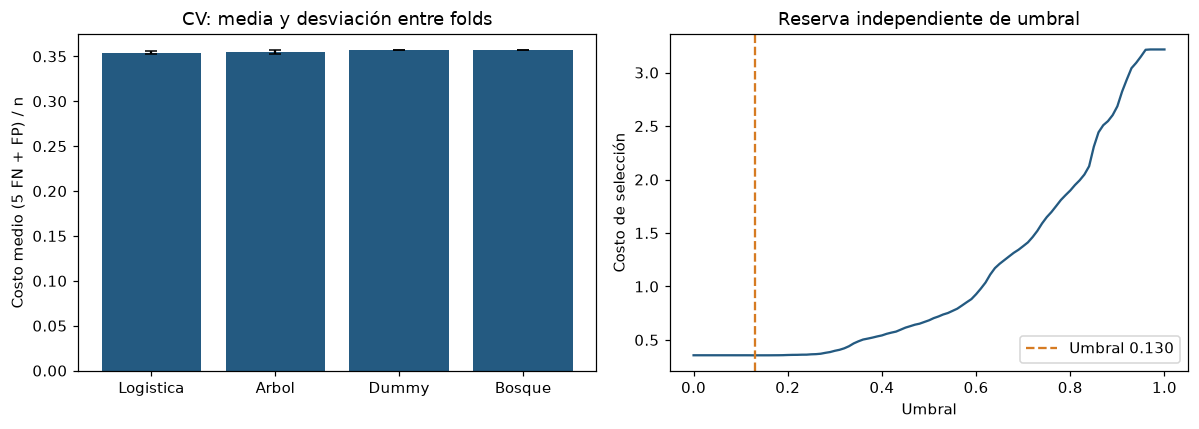

Importancia evaluada al umbral de referencia 1/6, no evidencia causal.


,variable,aumento_costo,sd
10,SITIOHABITUALCONSUMO_EST_EDUCATIVO,0.014621,0.002910
11,SITIOHABITUALCONSUMO_BARES_TABERNAS,0.013955,0.001227
9,SITIOHABITUALCONSUMO_PARQUE,0.012288,0.000831
3,CURSO_DE_VIDA,0.011732,0.002325
2,NOMBREUPZ,0.010510,0.001969
5,PERTENENCIAETNICA,0.009288,0.000786
1,NOMBRELOCALIDADRESIDENCIA,0.008732,0.001785
6,ESTADOCIVIL,0.008621,0.000875


In [7]:
# Visualización de estabilidad y compromiso costo-umbral, usando solo desarrollo.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(comparacion.modelo, comparacion.costo_cv, yerr=comparacion.sd_costo, color='#245a81', capsize=4)
axes[0].set(ylabel='Costo medio (5 FN + FP) / n', title='CV: media y desviación entre folds')
axes[1].plot(curva.umbral, curva.costo, color='#245a81')
axes[1].axvline(umbral_final, color='#d67b22', linestyle='--', label=f'Umbral {umbral_final:.3f}')
axes[1].set(xlabel='Umbral', ylabel='Costo de selección', title='Reserva independiente de umbral')
axes[1].legend()
fig.tight_layout()
fig.savefig('validacion_y_umbral.png', dpi=160)
plt.show()

# Importancia por permutación en reserva; mide reproducción de reglas, no causalidad.
importancias = permutation_importance(modelo_final, X_umbral, Y_umbral,
    scoring=puntuacion_costo, n_repeats=3, random_state=SEMILLA, max_samples=3000, n_jobs=1)
tabla_importancia = pd.DataFrame({'variable': X_umbral.columns,
    'aumento_costo': importancias.importances_mean, 'sd': importancias.importances_std})
tabla_importancia.sort_values('aumento_costo', ascending=False).to_csv('importancia_permutacion.csv', index=False)
print('Importancia evaluada al umbral de referencia 1/6, no evidencia causal.')
display(tabla_importancia.sort_values('aumento_costo', ascending=False).head(8))

### Evaluación final única en prueba
La familia, sus hiperparámetros y el umbral ya están congelados. Esta celda realiza una
única predicción probabilística en X_test y calcula todas las métricas a partir de ella.
El baseline constante usa la prevalencia de desarrollo, sin ajustarse a prueba. Las bandas
bootstrap describen incertidumbre condicional a este ajuste; no incluyen incertidumbre
de otras semillas, simuladores, dependencias de eventos ni cambios de población.
No se permite volver a seleccionar modelos o umbrales después de observar estas cifras.

Modelo final: Logistica | Umbral: 0.13


,modelo,umbral,n,TN,FP,FN,TP,costo,sensibilidad,precision,especificidad,f1,accuracy,auc,pr_auc,brier,fraccion_alertas,IC95_costo,IC95_ahorro_vs_dummy
0,Logistica,0.130000,20300,23,7219,3,13055,0.356355,0.99977,0.643928,0.003176,0.783331,0.644236,0.76144,0.849733,0.186192,0.998719,"[0.35004433497536946, 0.36295935960591136]","[-0.000541871921182266, 0.001232758620689654]"
1,Dummy referencia,0.166667,20300,0,7242,0,13058,0.356749,1.00000,0.643251,0.000000,0.782901,0.643251,0.50000,0.643251,0.229479,1.000000,NaN,NaN


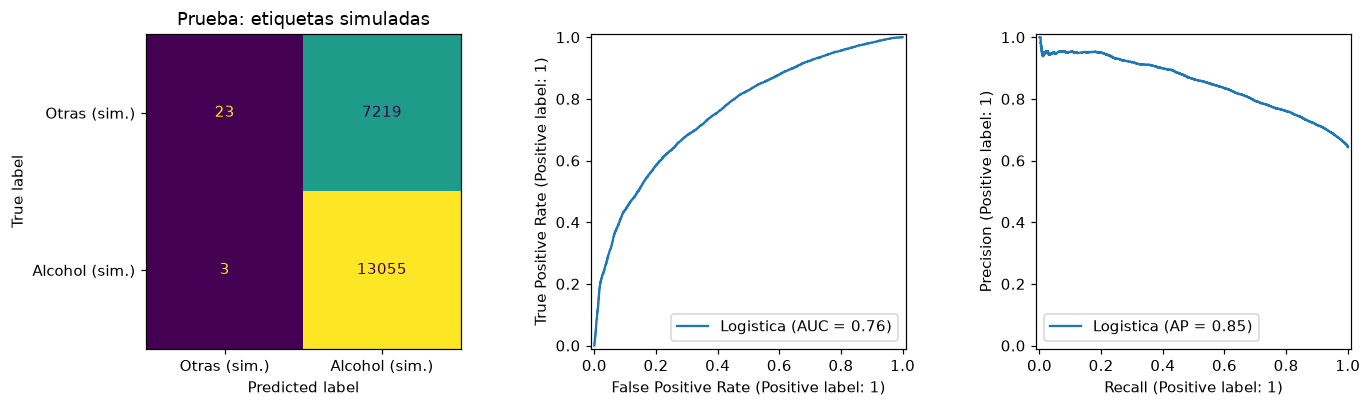

Evaluación final terminada. No modificar decisiones en función de prueba.


In [8]:
# Único acceso evaluativo a prueba: no hay entrenamiento ni selección posterior.
prob_test = modelo_final.predict_proba(X_test)[:, 1]
resultado_test = medir(Y_test, prob_test, umbral_final)
prob_dummy = np.full(len(Y_test), float(Y_desarrollo.mean()))
resultado_dummy = medir(Y_test, prob_dummy, UMBRAL_REFERENCIA)
pred_test = prob_test >= umbral_final
y_test_array = Y_test.to_numpy()
costos_individuales = C_FN * ((y_test_array == 1) & ~pred_test) + C_FP * ((y_test_array == 0) & pred_test)
pred_dummy = prob_dummy >= UMBRAL_REFERENCIA
costos_dummy = C_FN * ((y_test_array == 1) & ~pred_dummy) + C_FP * ((y_test_array == 0) & pred_dummy)
rng_boot = np.random.default_rng(SEMILLA + 2)
bootstrap = []
for repeticion in range(400):
    # Remuestreo pareado de predicciones ya calculadas: no se consulta otra vez el modelo.
    idx = rng_boot.integers(0, len(y_test_array), len(y_test_array))
    bootstrap.append([costos_individuales[idx].mean(), (costos_dummy[idx] - costos_individuales[idx]).mean()])
intervalos = np.quantile(np.array(bootstrap), [0.025, 0.975], axis=0)
resultado_test['IC95_costo'] = intervalos[:, 0].tolist()
resultado_test['IC95_ahorro_vs_dummy'] = intervalos[:, 1].tolist()
print('Modelo final:', nombre_final, '| Umbral:', umbral_final)
display(pd.DataFrame([{'modelo': nombre_final, **resultado_test}, {'modelo': 'Dummy referencia', **resultado_dummy}]))

# Todas las figuras finales se derivan de la única predicción anterior.
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
ConfusionMatrixDisplay.from_predictions(Y_test, pred_test, labels=[0, 1],
    display_labels=['Otras (sim.)', 'Alcohol (sim.)'], colorbar=False, ax=axes[0])
RocCurveDisplay.from_predictions(Y_test, prob_test, ax=axes[1], name=nombre_final)
PrecisionRecallDisplay.from_predictions(Y_test, prob_test, ax=axes[2], name=nombre_final)
axes[0].set_title('Prueba: etiquetas simuladas')
fig.tight_layout()
fig.savefig('evaluacion_final.png', dpi=160)
plt.show()

# Evidencia portable; no se serializa un modelo destinado a uso clínico.
resultados = {'semilla': SEMILLA, 'sha256_datos': SHA256, 'versiones': versiones,
    'etiqueta_simulada': True, 'filas_crudas': len(df), 'columnas_crudas': len(df.columns),
    'n_desarrollo': len(X_desarrollo), 'n_umbral': len(X_umbral), 'n_test': len(X_test),
    'positivos_desarrollo': int(Y_desarrollo.sum()), 'positivos_umbral': int(Y_umbral.sum()),
    'positivos_test': int(Y_test.sum()),
    'columnas_transformadas': int(modelo_final[:-1].transform(X_desarrollo.iloc[:1]).shape[1]),
    'modelo_final': nombre_final, 'parametros': busquedas[nombre_final].best_params_,
    'umbral_final': umbral_final, 'costo_FN': C_FN, 'costo_FP': C_FP,
    'test': resultado_test, 'baseline_test': resultado_dummy,
    'comparacion_cv': comparacion.to_dict(orient='records')}
Path('resultados.json').write_text(json.dumps(resultados, indent=2, ensure_ascii=False), encoding='utf-8')
print('Evaluación final terminada. No modificar decisiones en función de prueba.')

## 6. Despliegue, límites y gobernanza · R18
El entregable es un experimento reproducible para discusión académica, sin despliegue asistencial.
Una ventaja frente a Dummy solo muestra aprendizaje del generador sintético. La reserva de
umbral puede demandar evaluar una proporción muy alta de registros; no equivale a viabilidad.
La variabilidad CV describe estabilidad entre estas particiones, no validez del resultado real.
Una brecha entre costo de entrenamiento y CV sugiere sobreajuste; ambos altos sugieren
capacidad insuficiente o ruido irreducible. No hay descomposición causal formal de sesgo-varianza.

Antes de un piloto real se requieren etiquetas observadas multietiqueta cuando corresponda,
verificación de unidad de análisis, partición temporal y por persona, costos acordados y capacidad
de atención. Responsables propuestos (no asignaciones históricas): custodio de datos valida
procedencia y permisos; equipo analítico valida estabilidad y sesgos; responsable de salud
aprueba el uso y la supervisión humana. En un eventual piloto, revisar mensualmente faltantes,
categorías nuevas, deriva y carga de alertas; evaluar sensibilidad y precisión cuando maduren
las etiquetas. Suspender ante cambio de definición del resultado, falta de etiquetas confiables,
fallo de calidad o perjuicio desigual no resuelto. No tomar decisiones individuales automáticas.

### Trazabilidad y equipo
Las secciones R10–R18 se consolidan ahora. No prueban entregas históricas ni participación
individual. Los nombres proceden del notebook original; las contribuciones deben ser confirmadas
por el equipo. Véanse `trazabilidad_CRISP_DM.md` y `declaracion_IA.md`.

### Referencias
- Secretaría Distrital de Salud. (s. f.). *Consumo abusivo o problemático de sustancias psicoactivas* [Conjunto de datos]. Datos Abiertos Bogotá. https://datosabiertos.bogota.gov.co/dataset/consumo-abusivo-o-problematico-de-sustancias-psicoactivas
- Secretaría Distrital de Salud. (s. f.). *Consumo abusivo o problemático de sustancias psicoactivas en Bogotá D. C.* SaluData. https://saludata.saludcapital.gov.co/osb/indicadores/consumo-abusivo-spa/
- Chapman, P., Clinton, J., Kerber, R., Khabaza, T., Reinartz, T., Shearer, C., & Wirth, R. (2000). *CRISP-DM 1.0: Step-by-step data mining guide*. SPSS.
- Scikit-learn developers. (s. f.). *Common pitfalls and recommended practices*. https://scikit-learn.org/stable/common_pitfalls.html
- Scikit-learn developers. (s. f.). *Tuning the decision threshold for class prediction*. https://scikit-learn.org/stable/modules/classification_threshold.html